In [1]:
import os, re, string, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.neural_network import MLPClassifier
import joblib

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = "bbc-news-data.csv"
df = pd.read_csv(DATA_PATH, sep=None, engine="python")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (2225, 4)
Columns: ['category', 'filename', 'title', 'content']


,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...


Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   category  2225 non-null   object
 1   filename  2225 non-null   object
 2   title     2225 non-null   object
 3   content   2225 non-null   object
dtypes: object(4)
memory usage: 69.7+ KB


None

\nMissing values by column:


,missing_values
category,0
filename,0
title,0
content,0


\nDuplicate rows: 0
\nCategory counts:


,article_count
category,
sport,511
business,510
politics,417
tech,401
entertainment,386


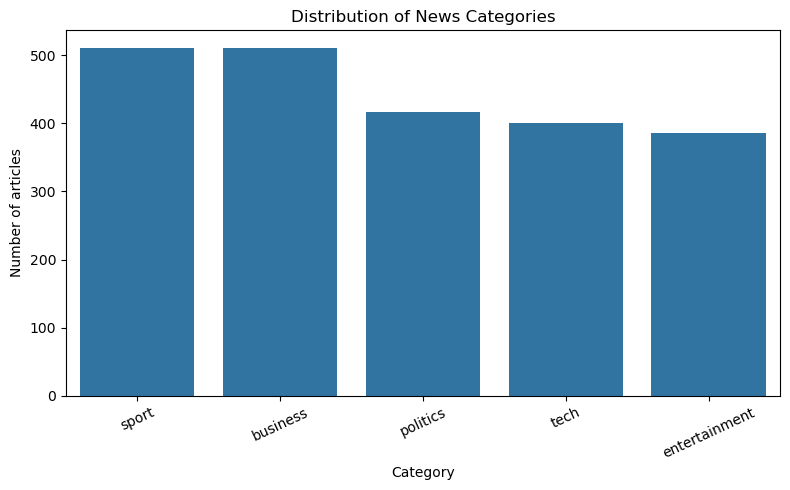

In [3]:
print("Dataset info:")
display(df.info())

print("\\nMissing values by column:")
display(df.isnull().sum().to_frame("missing_values"))

print("\\nDuplicate rows:", df.duplicated().sum())
print("\\nCategory counts:")
display(df["category"].value_counts().to_frame("article_count"))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="category", order=df["category"].value_counts().index)
plt.title("Distribution of News Categories")
plt.xlabel("Category")
plt.ylabel("Number of articles")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

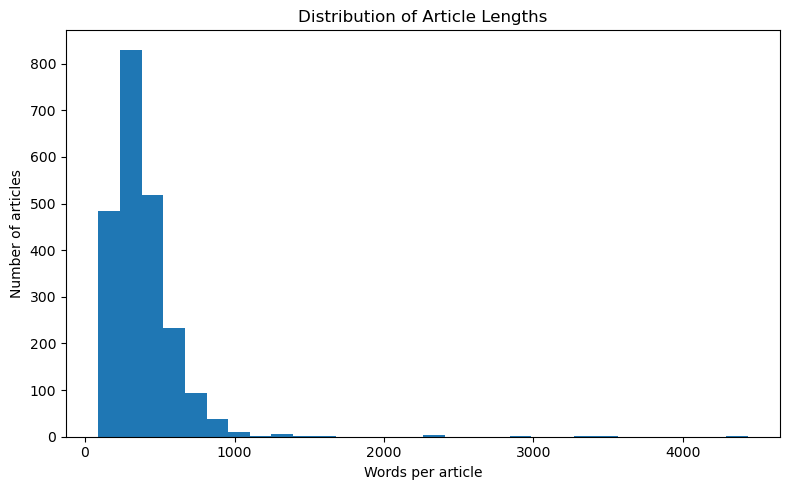

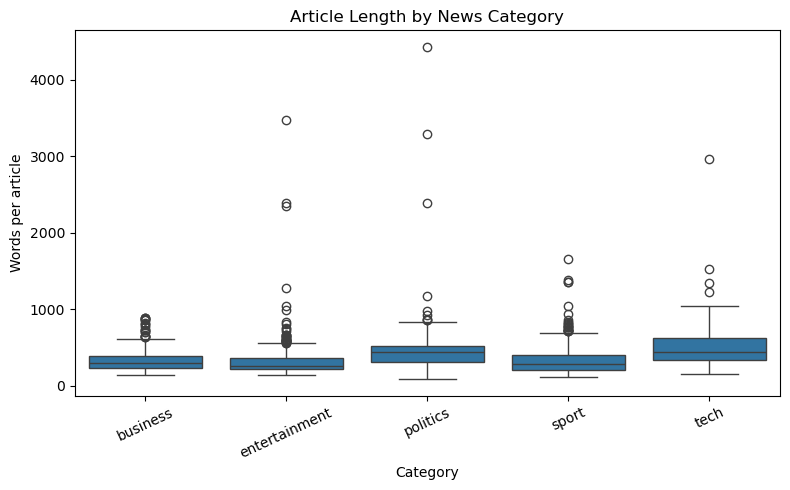

Total articles: 2225
Number of categories: 5
Categories: ['business', 'entertainment', 'politics', 'sport', 'tech']
Average article length: 384.04


In [4]:
for col in ["category", "title", "content"]:
    df[col] = df[col].fillna("").astype(str)

df["combined_text"] = (df["title"].str.strip() + " " + df["content"].str.strip()).str.strip()
df["word_count"] = df["combined_text"].apply(lambda x: len(x.split()))

plt.figure(figsize=(8, 5))
plt.hist(df["word_count"], bins=30)
plt.title("Distribution of Article Lengths")
plt.xlabel("Words per article")
plt.ylabel("Number of articles")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="category", y="word_count")
plt.title("Article Length by News Category")
plt.xlabel("Category")
plt.ylabel("Words per article")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

print("Total articles:", len(df))
print("Number of categories:", df["category"].nunique())
print("Categories:", sorted(df["category"].unique()))
print("Average article length:", round(df["word_count"].mean(), 2))

In [5]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

for resource in ["stopwords", "punkt", "punkt_tab"]:
    try:
        nltk.download(resource, quiet=True)
    except Exception:
        pass

try:
    STOP_WORDS = set(stopwords.words("english"))
except LookupError:
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    STOP_WORDS = set(ENGLISH_STOP_WORDS)

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\\S+|www\\.\\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    try:
        tokens = word_tokenize(text)
    except LookupError:
        tokens = re.findall(r"[a-z]+", text)
    tokens = [t for t in tokens if t.isalpha() and t not in STOP_WORDS and len(t) > 1]
    return tokens

df["tokens"] = df["combined_text"].apply(preprocess_text)
df["processed_text"] = df["tokens"].apply(lambda toks: " ".join(toks))

display(df[["category", "title", "processed_text"]].head(3))
print("Empty processed documents:", (df["processed_text"].str.len() == 0).sum())

,category,title,processed_text
0,business,Ad sales boost Time Warner profit,ad sales boost time warner profit quarterly pr...
1,business,Dollar gains on Greenspan speech,dollar gains greenspan speech dollar hit highe...
2,business,Yukos unit buyer faces loan claim,yukos unit buyer faces loan claim owners embat...


Empty processed documents: 0


##  Train-test split and label encoding

In [6]:
X_text = df["processed_text"].tolist()
y_text = df["category"].tolist()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)
class_names = list(label_encoder.classes_)

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))
print("Classes:", class_names)


Training samples: 1780
Testing samples: 445
Classes: [np.str_('business'), np.str_('entertainment'), np.str_('politics'), np.str_('sport'), np.str_('tech')]


## Feature extraction — Bag of Words and TF-IDF

In [7]:
bow_vectorizer = CountVectorizer(max_features=15000, min_df=2, max_df=0.98)
tfidf_vectorizer = TfidfVectorizer(max_features=15000, min_df=2, max_df=0.98, ngram_range=(1, 2))

X_train_bow = bow_vectorizer.fit_transform(X_train_text)
X_test_bow = bow_vectorizer.transform(X_test_text)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)
X_test_tfidf = tfidf_vectorizer.transform(X_test_text)

print("BoW train shape:", X_train_bow.shape)
print("TF-IDF train shape:", X_train_tfidf.shape)
print("BoW sparsity (%):", round(100 * (1 - X_train_bow.nnz / np.prod(X_train_bow.shape)), 2))
print("TF-IDF sparsity (%):", round(100 * (1 - X_train_tfidf.nnz / np.prod(X_train_tfidf.shape)), 2))

top_terms = sorted(bow_vectorizer.vocabulary_.items(), key=lambda kv: kv[1])[:20]
print("Example vocabulary terms:", [t for t, _ in top_terms])

BoW train shape: (1780, 15000)
TF-IDF train shape: (1780, 15000)
BoW sparsity (%): 99.04
TF-IDF sparsity (%): 98.93
Example vocabulary terms: ['aaa', 'aaas', 'aac', 'aaron', 'abandon', 'abandoned', 'abandoning', 'abandonment', 'abba', 'abbas', 'abbasi', 'abbott', 'abc', 'abdellatif', 'abdication', 'aberdeen', 'abide', 'abided', 'abiding', 'abilities']


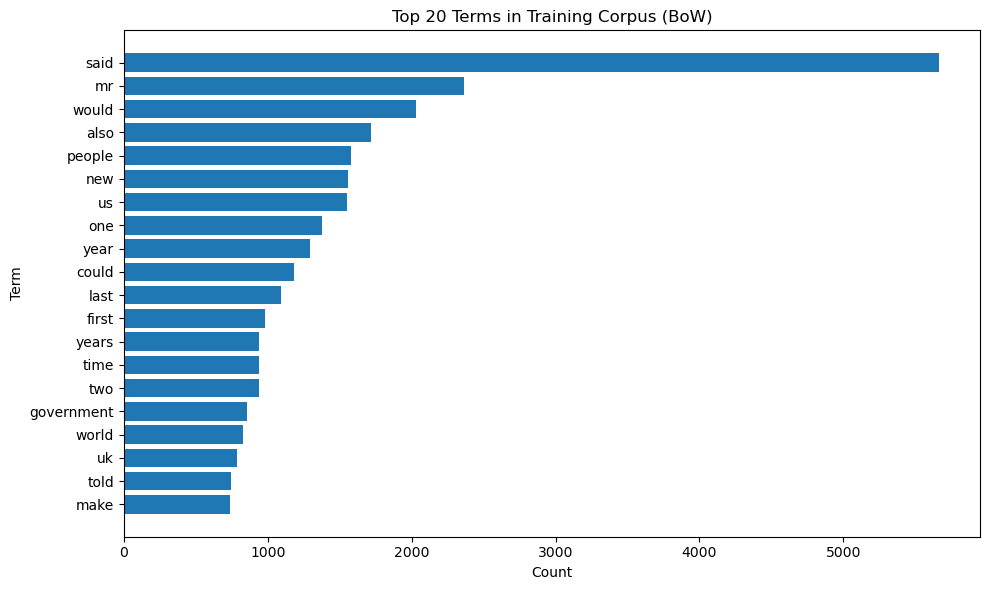

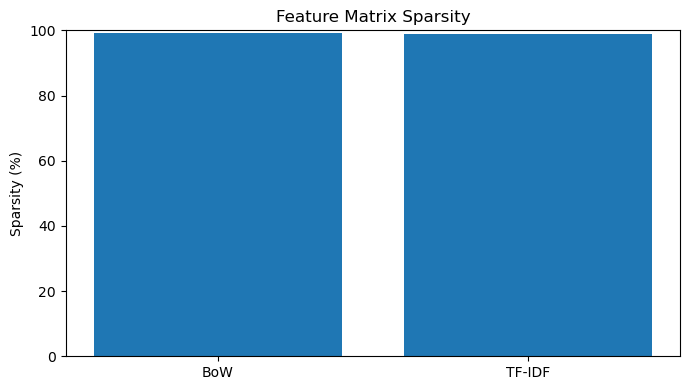

In [8]:
# Plot top 20 terms by corpus frequency using the BoW matrix
term_counts = np.asarray(X_train_bow.sum(axis=0)).ravel()
terms = np.array(bow_vectorizer.get_feature_names_out())
top_idx = np.argsort(term_counts)[-20:]

plt.figure(figsize=(10, 6))
plt.barh(terms[top_idx], term_counts[top_idx])
plt.title("Top 20 Terms in Training Corpus (BoW)")
plt.xlabel("Count")
plt.ylabel("Term")
plt.tight_layout()
plt.show()

# Sparsity comparison
bow_sparsity = 100 * (1 - X_train_bow.nnz / np.prod(X_train_bow.shape))
tfidf_sparsity = 100 * (1 - X_train_tfidf.nnz / np.prod(X_train_tfidf.shape))
plt.figure(figsize=(7, 4))
plt.bar(["BoW", "TF-IDF"], [bow_sparsity, tfidf_sparsity])
plt.title("Feature Matrix Sparsity")
plt.ylabel("Sparsity (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## Feature extraction — Word2Vec

In [9]:
%pip install gensim

Note: you may need to restart the kernel to use updated packages.


In [10]:
try:
    from gensim.models import Word2Vec
except ImportError as e:
    raise ImportError("Install Gensim first with: %pip install gensim") from e

word2vec_model = Word2Vec(
    sentences=df["tokens"].tolist(),
    vector_size=100,
    window=5,
    min_count=2,
    workers=2,
    sg=1,
    epochs=15,
    seed=RANDOM_STATE
)

def document_vector(tokens, model, dim=100):
    vectors = [model.wv[w] for w in tokens if w in model.wv]
    if not vectors:
        return np.zeros(dim, dtype=np.float32)
    return np.mean(vectors, axis=0).astype(np.float32)

X_w2v = np.vstack([document_vector(toks, word2vec_model) for toks in df["tokens"]])
X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v = train_test_split(
    X_w2v, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Word2Vec document matrix:", X_w2v.shape)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Word2Vec document matrix: (2225, 100)


## Model 1 — Feed-forward Neural Network (NN)

In [11]:
nn_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=1e-4,
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=40,
    early_stopping=True,
    random_state=RANDOM_STATE,
    verbose=False
)
nn_model.fit(X_train_tfidf, y_train)
nn_pred = nn_model.predict(X_test_tfidf)
print(classification_report(y_test, nn_pred, target_names=class_names, zero_division=0))

               precision    recall  f1-score   support

     business       1.00      0.97      0.99       102
entertainment       0.99      1.00      0.99        77
     politics       0.99      0.98      0.98        84
        sport       0.99      1.00      1.00       102
         tech       0.98      1.00      0.99        80

     accuracy                           0.99       445
    macro avg       0.99      0.99      0.99       445
 weighted avg       0.99      0.99      0.99       445



## Model 2 — Word2Vec + Neural Network

In [12]:
w2v_nn = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    max_iter=300,
    early_stopping=True,
    random_state=RANDOM_STATE
)
w2v_nn.fit(X_train_w2v, y_train_w2v)
w2v_pred = w2v_nn.predict(X_test_w2v)
print(classification_report(y_test_w2v, w2v_pred, target_names=class_names, zero_division=0))

               precision    recall  f1-score   support

     business       0.97      0.93      0.95       102
entertainment       0.96      0.97      0.97        77
     politics       0.89      0.93      0.91        84
        sport       1.00      0.98      0.99       102
         tech       0.94      0.95      0.94        80

     accuracy                           0.95       445
    macro avg       0.95      0.95      0.95       445
 weighted avg       0.95      0.95      0.95       445



## Model 3 — Recurrent Neural Network (RNN)

In [13]:
import re
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from collections import Counter

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Keep sequences shorter for faster, more stable training on CPU.
MAX_WORDS = 20000
MAX_LEN = 200
BATCH_SIZE = 32

# Build vocabulary from training texts only (avoids test-set leakage).
word_counts = Counter(word for text in X_train_text for word in text.split())
vocab = {"<PAD>": 0, "<OOV>": 1}
for word, _ in word_counts.most_common(MAX_WORDS - 2):
    vocab[word] = len(vocab)

def text_to_sequence(text):
    tokens = text.split()[:MAX_LEN]
    ids = [vocab.get(token, 1) for token in tokens]
    length = max(1, len(ids))
    ids += [0] * (MAX_LEN - len(ids))
    return ids, length

train_encoded = [text_to_sequence(text) for text in X_train_text]
test_encoded = [text_to_sequence(text) for text in X_test_text]

X_train_seq = np.asarray([item[0] for item in train_encoded], dtype=np.int64)
train_lengths = np.asarray([item[1] for item in train_encoded], dtype=np.int64)
X_test_seq = np.asarray([item[0] for item in test_encoded], dtype=np.int64)
test_lengths = np.asarray([item[1] for item in test_encoded], dtype=np.int64)

X_train_tensor = torch.tensor(X_train_seq, dtype=torch.long)
train_lengths_tensor = torch.tensor(train_lengths, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_seq, dtype=torch.long)
test_lengths_tensor = torch.tensor(test_lengths, dtype=torch.long)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# Split training data into train and validation sets.
indices = np.arange(len(X_train_tensor))
train_idx, val_idx = train_test_split(
    indices, test_size=0.15, random_state=RANDOM_STATE, stratify=y_train
)

train_loader = DataLoader(
    TensorDataset(X_train_tensor[train_idx], train_lengths_tensor[train_idx],
                  y_train_tensor[train_idx]),
    batch_size=BATCH_SIZE, shuffle=True
)
val_loader = DataLoader(
    TensorDataset(X_train_tensor[val_idx], train_lengths_tensor[val_idx],
                  y_train_tensor[val_idx]),
    batch_size=64, shuffle=False
)

class NewsRNN(nn.Module):
    """Bidirectional GRU classifier; packed sequences ignore padding tokens."""
    def __init__(self, vocab_size, num_classes, embedding_dim=64, hidden_size=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.gru = nn.GRU(
            input_size=embedding_dim, hidden_size=hidden_size,
            batch_first=True, bidirectional=True
        )
        self.dropout = nn.Dropout(0.35)
        self.fc = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, tokens, lengths):
        from torch.nn.utils.rnn import pack_padded_sequence
        embedded = self.embedding(tokens)
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, hidden = self.gru(packed)
        # Last layer's forward and backward final hidden states.
        features = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.fc(self.dropout(features))

rnn_model = NewsRNN(len(vocab), len(class_names)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(rnn_model.parameters(), lr=0.001, weight_decay=1e-5)

print("Vocabulary size:", len(vocab))
print("Sequence length:", MAX_LEN)
print("Training samples:", len(train_idx), "| Validation samples:", len(val_idx))


Using device: cpu
Vocabulary size: 20000
Sequence length: 200
Training samples: 1513 | Validation samples: 267


In [14]:
# Train with early stopping based on validation loss
EPOCHS = 12
PATIENCE = 3

history = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}
best_val_loss = float("inf")
best_state = None
patience_counter = 0

for epoch in range(EPOCHS):
    rnn_model.train()
    train_loss = train_correct = train_total = 0

    for xb, lengths, yb in train_loader:
        xb, lengths, yb = xb.to(device), lengths.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = rnn_model(xb, lengths)
        loss = criterion(logits, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(rnn_model.parameters(), max_norm=1.0)
        optimizer.step()
        train_loss += loss.item() * len(yb)
        train_correct += (logits.argmax(1) == yb).sum().item()
        train_total += len(yb)

    rnn_model.eval()
    val_loss = val_correct = val_total = 0
    with torch.no_grad():
        for xb, lengths, yb in val_loader:
            xb, lengths, yb = xb.to(device), lengths.to(device), yb.to(device)
            logits = rnn_model(xb, lengths)
            loss = criterion(logits, yb)
            val_loss += loss.item() * len(yb)
            val_correct += (logits.argmax(1) == yb).sum().item()
            val_total += len(yb)

    train_loss /= train_total
    val_loss /= val_total
    train_acc = train_correct / train_total
    val_acc = val_correct / val_total
    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | loss={train_loss:.4f} "
        f"| acc={train_acc:.4f} | val_loss={val_loss:.4f} "
        f"| val_acc={val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone()
                      for k, v in rnn_model.state_dict().items()}
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print("Early stopping: validation loss did not improve.")
            break

if best_state is not None:
    rnn_model.load_state_dict(best_state)

# Evaluate once on the held-out test set
rnn_model.eval()
with torch.no_grad():
    test_logits = rnn_model(X_test_tensor.to(device), test_lengths_tensor.to(device))
    rnn_prob = torch.softmax(test_logits, dim=1).cpu().numpy()
rnn_pred = np.argmax(rnn_prob, axis=1)

print("\\nPyTorch RNN Classification Report:")
print(classification_report(
    y_test, rnn_pred, labels=np.arange(len(class_names)),
    target_names=class_names, zero_division=0
))


Epoch 1/12 | loss=1.5830 | acc=0.2723 | val_loss=1.5361 | val_acc=0.3221
Epoch 2/12 | loss=1.4480 | acc=0.4402 | val_loss=1.4623 | val_acc=0.3970
Epoch 3/12 | loss=1.2356 | acc=0.5651 | val_loss=1.2328 | val_acc=0.4831
Epoch 4/12 | loss=0.8687 | acc=0.7006 | val_loss=0.9692 | val_acc=0.6442
Epoch 5/12 | loss=0.5537 | acc=0.8275 | val_loss=0.8589 | val_acc=0.7079
Epoch 6/12 | loss=0.3312 | acc=0.9061 | val_loss=0.6391 | val_acc=0.7940
Epoch 7/12 | loss=0.2110 | acc=0.9379 | val_loss=0.7232 | val_acc=0.7678
Epoch 8/12 | loss=0.1245 | acc=0.9722 | val_loss=0.5595 | val_acc=0.8127
Epoch 9/12 | loss=0.0774 | acc=0.9822 | val_loss=0.4482 | val_acc=0.8727
Epoch 10/12 | loss=0.0345 | acc=0.9960 | val_loss=0.4439 | val_acc=0.8764
Epoch 11/12 | loss=0.0276 | acc=0.9980 | val_loss=0.4326 | val_acc=0.8764
Epoch 12/12 | loss=0.0153 | acc=0.9993 | val_loss=0.4120 | val_acc=0.8876
\nPyTorch RNN Classification Report:
               precision    recall  f1-score   support

     business       0.93    

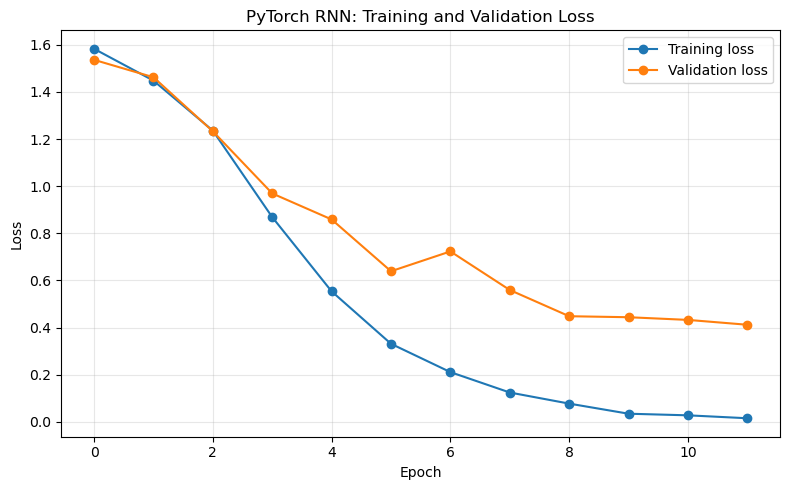

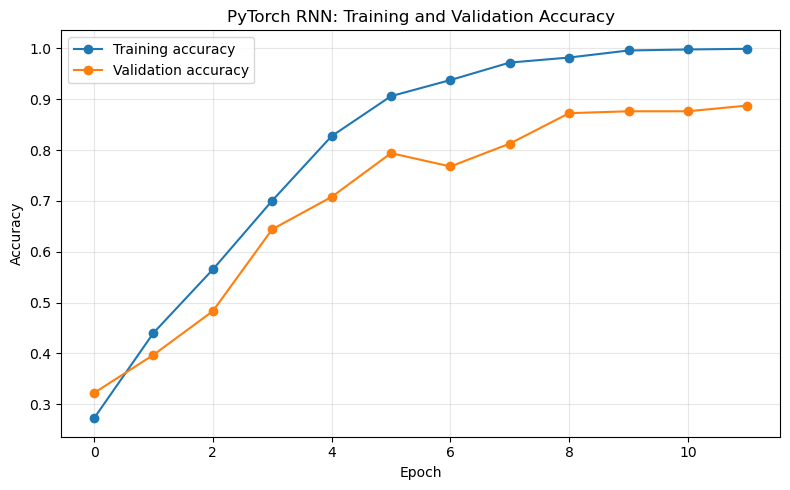

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history["loss"], marker="o", label="Training loss")
plt.plot(history["val_loss"], marker="o", label="Validation loss")
plt.title("PyTorch RNN: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history["accuracy"], marker="o", label="Training accuracy")
plt.plot(history["val_accuracy"], marker="o", label="Validation accuracy")
plt.title("PyTorch RNN: Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

##  Evaluation metrics and model comparison

,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted
0,NN (TF-IDF),0.9888,0.9889,0.9888,0.9887
1,NN (Word2Vec mean),0.9528,0.9538,0.9528,0.9531
2,RNN (sequence),0.8989,0.9038,0.8989,0.8994


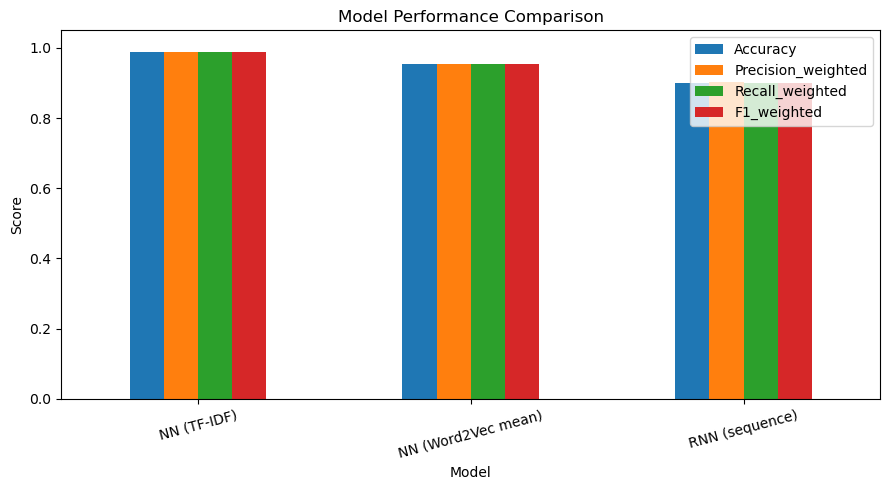

In [16]:
def metric_row(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_weighted": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall_weighted": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    }

results = [
    metric_row("NN (TF-IDF)", y_test, nn_pred),
    metric_row("NN (Word2Vec mean)", y_test_w2v, w2v_pred),
    metric_row("RNN (sequence)", y_test, rnn_pred)
]
results_df = pd.DataFrame(results).sort_values("F1_weighted", ascending=False)
display(results_df.style.format({c:"{:.4f}" for c in results_df.columns if c != "Model"}))

plt.figure(figsize=(9, 5))
results_df.set_index("Model")[["Accuracy", "Precision_weighted", "Recall_weighted", "F1_weighted"]].plot(kind="bar", ax=plt.gca())
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

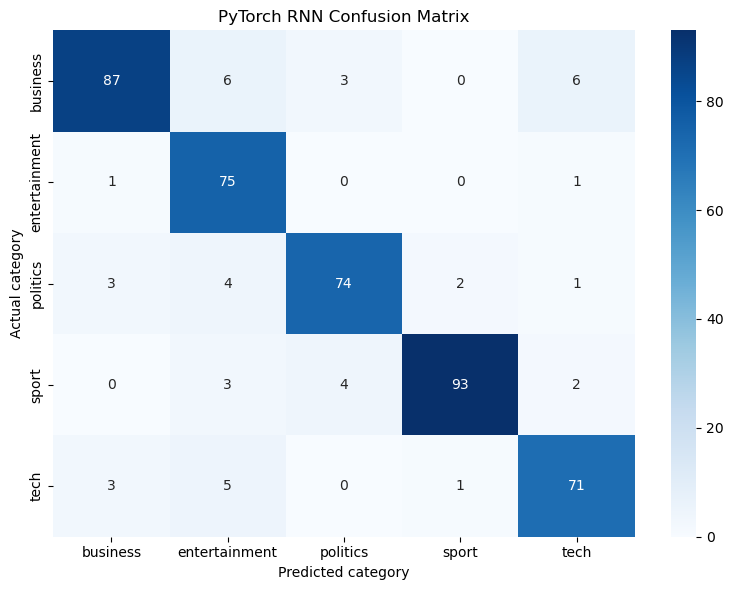

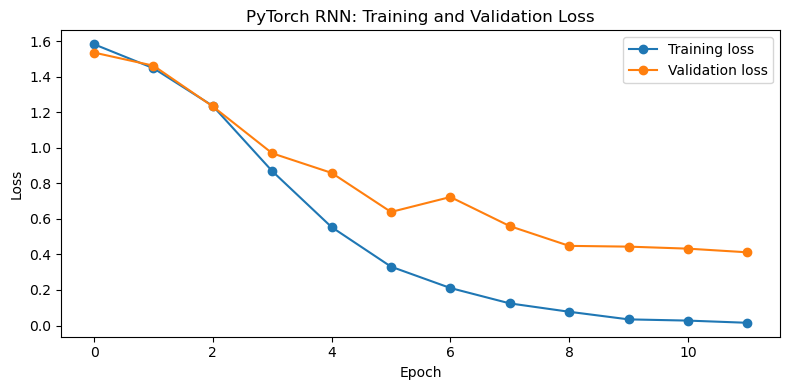

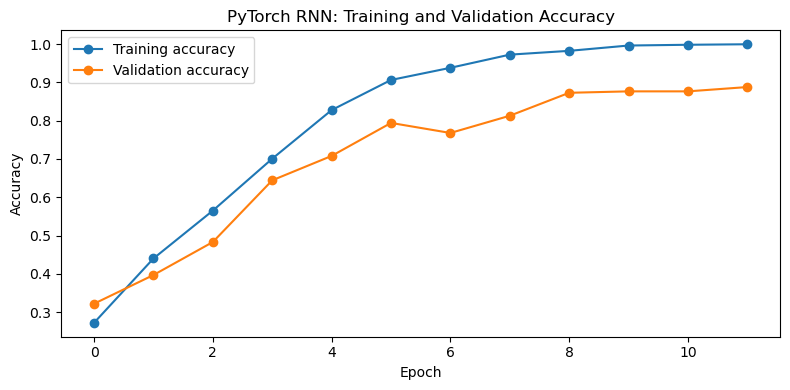

In [17]:
# Confusion matrix for the PyTorch RNN
cm = confusion_matrix(y_test, rnn_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("PyTorch RNN Confusion Matrix")
plt.xlabel("Predicted category")
plt.ylabel("Actual category")
plt.tight_layout()
plt.show()

# Training curves: history is a dictionary in the PyTorch implementation
plt.figure(figsize=(8, 4))
plt.plot(history["loss"], marker="o", label="Training loss")
plt.plot(history["val_loss"], marker="o", label="Validation loss")
plt.title("PyTorch RNN: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history["accuracy"], marker="o", label="Training accuracy")
plt.plot(history["val_accuracy"], marker="o", label="Validation accuracy")
plt.title("PyTorch RNN: Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

## Save trained model and artifacts


In [18]:
os.makedirs("lab9_artifacts", exist_ok=True)

# Save PyTorch model and the preprocessing information needed to reproduce inputs.
torch.save(rnn_model.state_dict(), "lab9_artifacts/flipitnews_rnn.pt")
with open("lab9_artifacts/vocab.json", "w", encoding="utf-8") as f:
    json.dump(vocab, f, ensure_ascii=False)
with open("lab9_artifacts/label_classes.json", "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False)
with open("lab9_artifacts/rnn_config.json", "w", encoding="utf-8") as f:
    json.dump({
        "max_len": MAX_LEN,
        "vocab_size": len(vocab),
        "num_classes": len(class_names),
        "embedding_dim": 64,
        "hidden_size": 64,
        "architecture": "bidirectional_gru"
    }, f, indent=2)

word2vec_model.save("lab9_artifacts/word2vec.model")
joblib.dump(tfidf_vectorizer, "lab9_artifacts/tfidf_vectorizer.joblib")
joblib.dump(nn_model, "lab9_artifacts/tfidf_nn.joblib")
results_df.to_csv("lab9_artifacts/model_metrics.csv", index=False)

print("Saved PyTorch model and artifacts to lab9_artifacts/")


Saved PyTorch model and artifacts to lab9_artifacts/
